## ELEC3705 Assignment 1
Oskar Meszaros (z5636164)

### Constants

In [1]:
# imports
from numpy import linalg as LA
from scipy.linalg import expm

import matplotlib.pyplot as plt
import numpy as np

import os

# meta
OUT_DIR = "figures"
try:
    os.mkdir(OUT_DIR)
except:
    pass

colour1 = "mediumorchid"
colour2 = "mediumseagreen"
colour3 = "lightsalmon"

# constants
gamma_n = 42.48e6 # Hz
gaussian_std = 10

# Standard vectors and Pauli matrices
d_ket = np.array([0, 1])
u_ket = np.array([1, 0])

sigma_x = np.array([[0, 1], [1, 0]])
sigma_y = np.array([[0, -1j], [1j, 0]])
sigma_z = np.array([[1, 0], [0, -1]])

# Nuclear spin matrices
I_x = sigma_x / 2
I_y = sigma_y / 2
I_z = sigma_z / 2

sigma = np.array([sigma_x, sigma_y, sigma_z])
I_vec = np.array([I_x, I_y, I_z])

# global configuration
plt.rcParams["font.size"] = 18
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["figure.figsize"] = (8, 5.5)
# plt.rcParams["axes.labelsize"] = "large"
plt.rcParams["savefig.dpi"] = 150


### Question 1.1

Rows: 255, Cols: 255


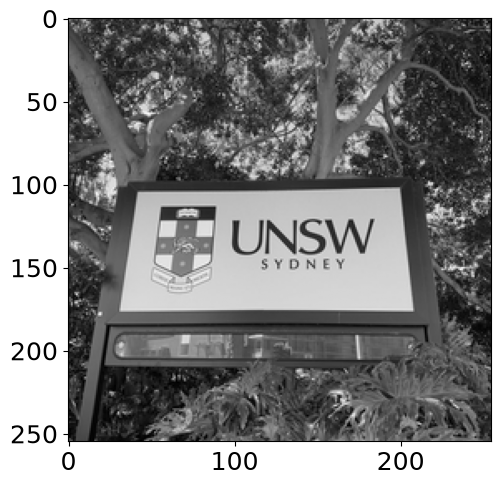

In [2]:
img = plt.imread("image.jpg").astype(float)

plt.imshow(img, cmap="gray")
nrows, ncols = img.shape
print(f"Rows: {nrows}, Cols: {ncols}")
plt.show()

### Question 1.2

 Mu | Column
  0 | 127
 20 | 147


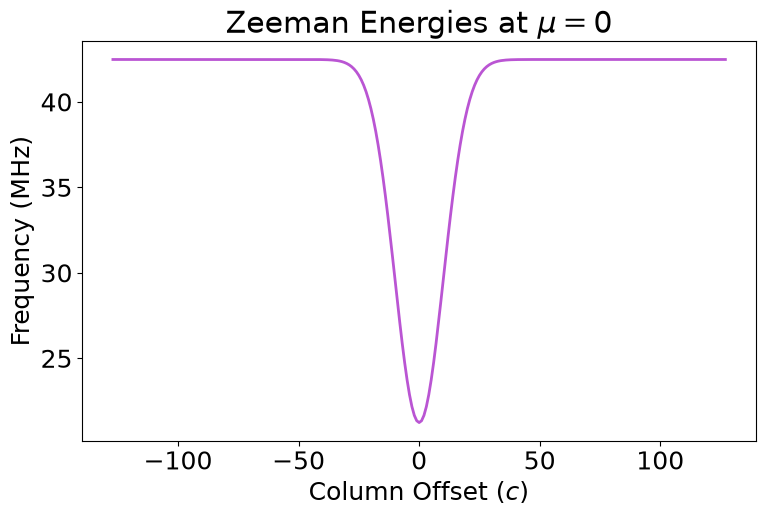

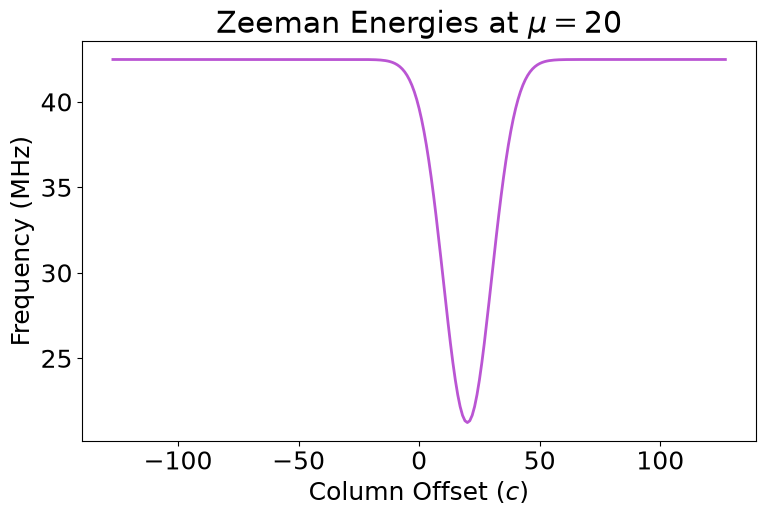

In [3]:
# Time-independent magnetic field B(c) = (0, 0, B_z)
def B_z(c, mu):
    # Gaussian
    G = np.exp(-((c - mu) ** 2) / (2 * gaussian_std**2)) / (
        gaussian_std * np.sqrt(2 * np.pi)
    )
    G_max = G.max()
    # B_z(c)
    return 1 - G / (2 * G_max)


mu_1 = 0
mu_2 = 20

# Columns centred on column 127
c = np.arange(ncols) - ncols // 2

# Create magnetic fields and find Zeeman energy
B1_z = B_z(c, mu_1)
E1_z = gamma_n * B1_z

B2_z = B_z(c, mu_2)
E2_z = gamma_n * B2_z

print(" Mu | Column")
print(f"  0 | {ncols//2}")
print(f" 20 | {ncols//2+20}")

# Plotting
for energies, label, file in zip(
    [E1_z, E2_z], [r"$\mu=0$", r"$\mu=20$"], ["zeeman-mu00.png", "zeeman-mu20.png"]
):
    fig = plt.figure()
    ax = fig.add_subplot()
    ax.plot(c, energies / 1e6, color=colour1)
    ax.set_title(f"Zeeman Energies at {label}")
    ax.set_xlabel(r"Column Offset ($c$)")
    ax.set_ylabel("Frequency (MHz)")
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/{file}")


### Question 1.3

In [4]:
# Total magnetic field (only the time-independent z-component)
B_vec = np.stack([np.zeros(ncols), np.zeros(ncols), B_z(c, 0)], axis=1)
# Construct hamiltonian using Einstein notation because most reliable method I have found
hamiltonian = np.real(gamma_n * np.einsum("ci,ijk->cjk", B_vec, I_vec))

print("Calculated")
print(f"Centre Hamiltonian ({ncols//2}, 0) (Hz):", hamiltonian[ncols // 2], sep="\n") # should be 1/4*gamma_n*sigma_z
print(f"Last Hamiltonian ({ncols-1}, {(ncols-1)-ncols//2}) (Hz):", hamiltonian[ncols - 1], sep="\n")  # should be 1/2*gamma_n*sigma_z
print("\nPredicted")
print(f"Centre Hamiltonian:", 1/4*gamma_n*sigma_z, sep="\n")
print(f"Last Hamiltonian:", 1/2*gamma_n*sigma_z, sep="\n")

Calculated
Centre Hamiltonian (127, 0) (Hz):
[[ 10620000.         0.]
 [        0. -10620000.]]
Last Hamiltonian (254, 127) (Hz):
[[ 21240000.         0.]
 [        0. -21240000.]]

Predicted
Centre Hamiltonian:
[[ 10620000.         0.]
 [        0. -10620000.]]
Last Hamiltonian:
[[ 21240000.         0.]
 [        0. -21240000.]]


### Question 1.4

In [5]:
B_amp = 0.05 # T
f_drive = gamma_n * 0.5 # gamma_n * B_z(0)
omega_R = gamma_n * B_amp / 2
delta = gamma_n * B1_z - f_drive
# Hamiltonian in the rotating frame
H_tilde = delta[:, None, None] * I_z + omega_R * I_x


print(Hp _tilde[ncols // 2])
print(H_tilde[ncols - 1])

[[     0. 531000.]
 [531000.      0.]]
[[ 10620000.    531000.]
 [   531000. -10620000.]]


### Question 1.5

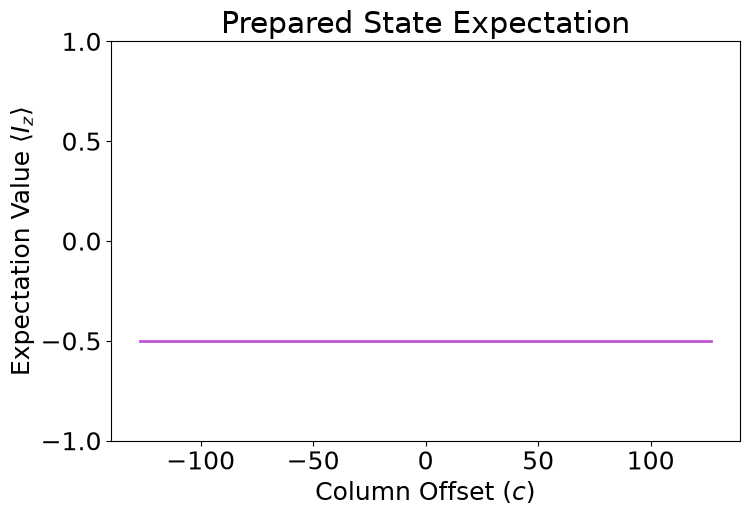

In [6]:
states = np.tile(d_ket, (ncols, 1))  # set one spin per pixel
expect = np.real(np.einsum("...i,ij,...j->...", states.conj(), I_z, states))

fig, ax = plt.subplots()
ax.plot(c, expect, color=colour1)

ax.set_title("Prepared State Expectation")
ax.set_xlabel(r"Column Offset ($c$)")
ax.set_ylabel(r"Expectation Value $\langle I_z \rangle$")
ax.set_ylim(-1, 1) # view the entire range of expectation values
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/single-spin-exp.png")


### Question 1.6

Omega_R = 1.062 MHz, T_rabi = 0.942 us


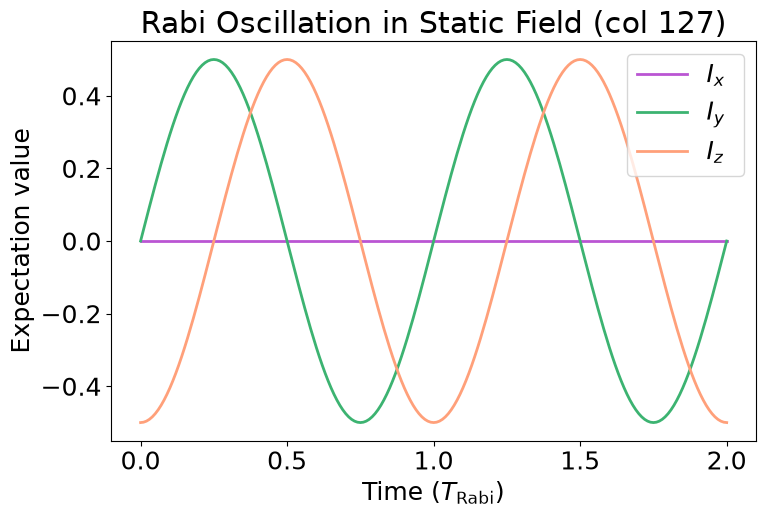

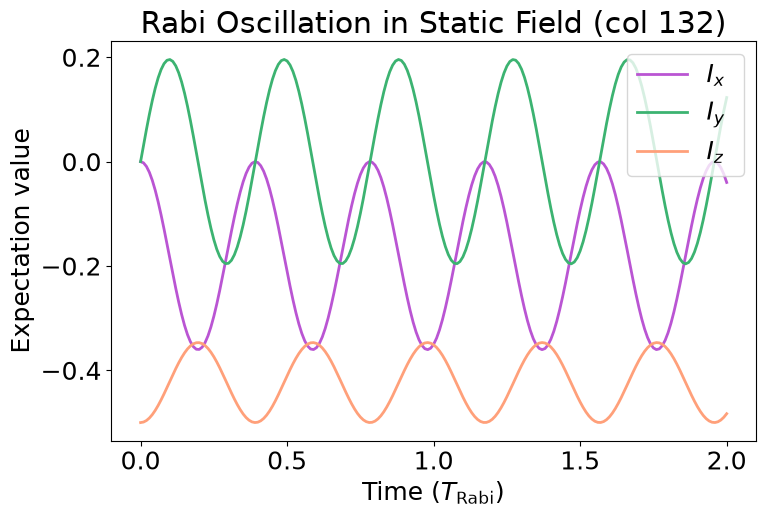

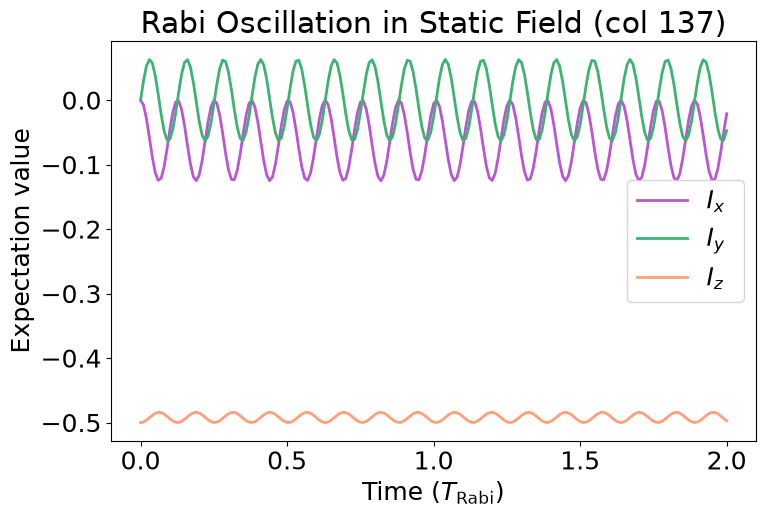

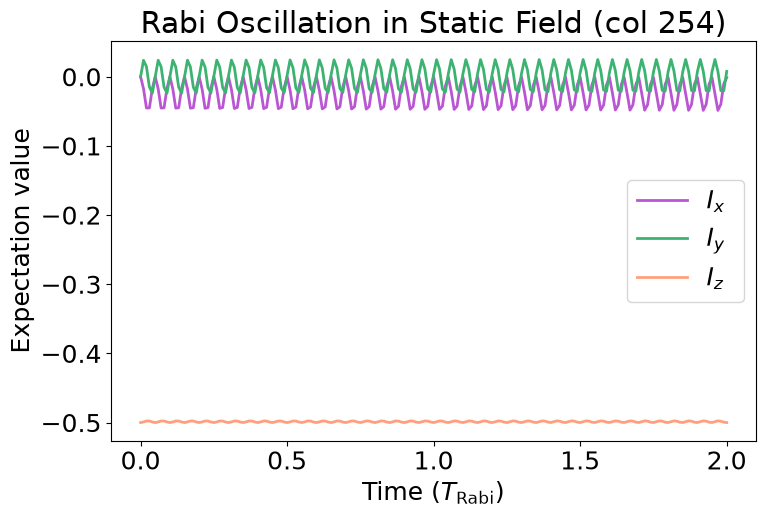

In [7]:
T_rabi = 1 / omega_R
# t = np.arange(0, 2 * T_rabi + T_rabi / 200, T_rabi / 100)
t = np.linspace(0, 2 * T_rabi, 201)

cols = [ncols // 2, ncols // 2 + 5, ncols // 2 + 10, ncols - 1]

psi_0 = d_ket

print(f"Omega_R = {omega_R/1e6:.3f} MHz, T_rabi = {T_rabi*1e6:.3f} us")


for col in cols:
    psi = np.array([expm(-1j * 2 * np.pi * H_tilde[col] * tk) @ psi_0 for tk in t])

    Ix_exp = np.real(np.einsum("...i,ij,...j->...", psi.conj(), I_x, psi))
    Iy_exp = np.real(np.einsum("...i,ij,...j->...", psi.conj(), I_y, psi))
    Iz_exp = np.real(np.einsum("...i,ij,...j->...", psi.conj(), I_z, psi))

    fig = plt.figure()
    ax = fig.add_subplot()
    label_col = f"{col - ncols // 2:03}"
    ax.plot(t / T_rabi, Ix_exp, label=r"$I_x$ ", color=colour1)
    ax.plot(t / T_rabi, Iy_exp, label=r"$I_y$ ", color=colour2)
    ax.plot(t / T_rabi, Iz_exp, label=r"$I_z$ ", color=colour3)

    ax.set_title(f"Rabi Oscillation in Static Field (col {col})")
    ax.set_xlabel(r"Time ($T_{\mathrm{Rabi}}$)")
    ax.set_ylabel(r"Expectation value")
    ax.legend()
    #ax.legend(loc="center right", framealpha=0.9)
    
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/single-spin-rabi-{label_col}.png")


### Question 1.7

Pulse Duration: 2.3540489642184557e-07s, 0.23540489642184556us


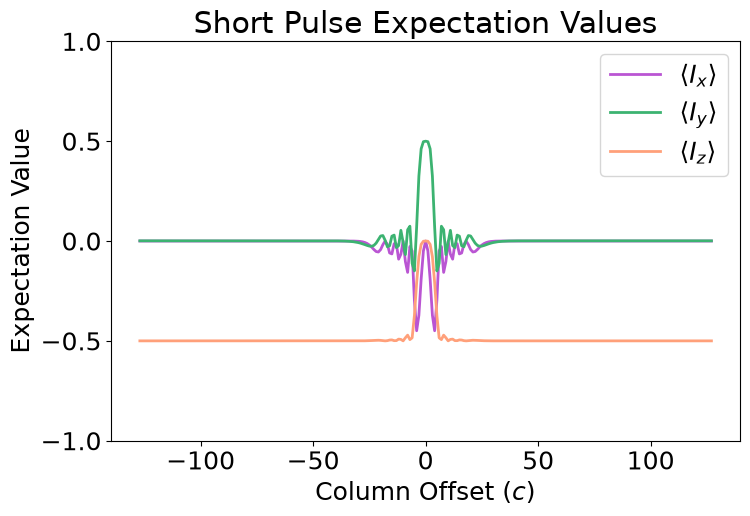

In [8]:
t_pi2 = T_rabi / 4

psi0 = np.array([0, 1], dtype=complex)
psi_pi2 = np.array(
    [expm(-1j * 2 * np.pi * H_tilde[col] * t_pi2) @ psi0 for col in range(ncols)]
)  # (ncols, 2)

Ix_exp = np.real(np.einsum("ci,ij,cj->c", psi_pi2.conj(), I_x, psi_pi2))
Iy_exp = np.real(np.einsum("ci,ij,cj->c", psi_pi2.conj(), I_y, psi_pi2))
Iz_exp = np.real(np.einsum("ci,ij,cj->c", psi_pi2.conj(), I_z, psi_pi2))

fig, ax = plt.subplots()
ax.plot(c, Ix_exp, color=colour1, linewidth=2, label=r"$\langle I_x\rangle$")
ax.plot(c, Iy_exp, color=colour2, linewidth=2, label=r"$\langle I_y\rangle$")
ax.plot(c, Iz_exp, color=colour3, linewidth=2, label=r"$\langle I_z\rangle$")
ax.set_title("Short Pulse Expectation Values")
ax.set_xlabel(r"Column Offset ($c$)")
ax.set_ylabel("Expectation Value")
ax.set_ylim(-1,1)
ax.legend()
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/single-spin-pulse.png")

print(f"Pulse Duration: {t_pi2}s, {t_pi2*1e6}us")


### Question 1.8

T_Larmor = 47.081 ns
[[ 10620000.         0.]
 [        0. -10620000.]]


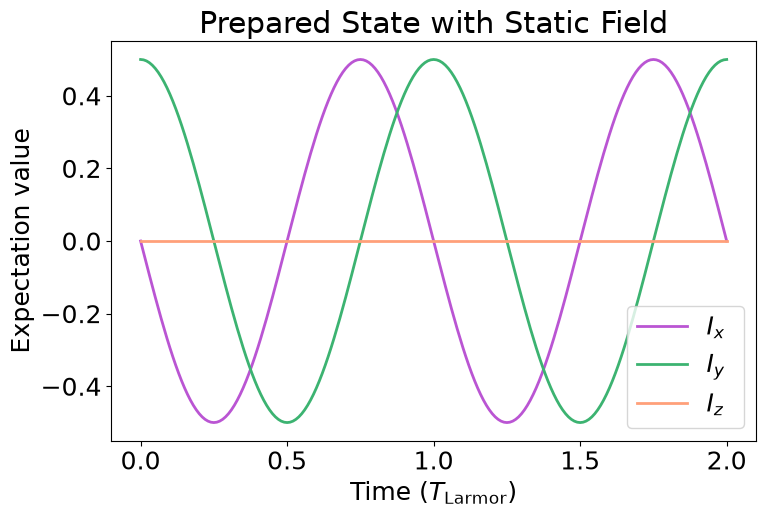

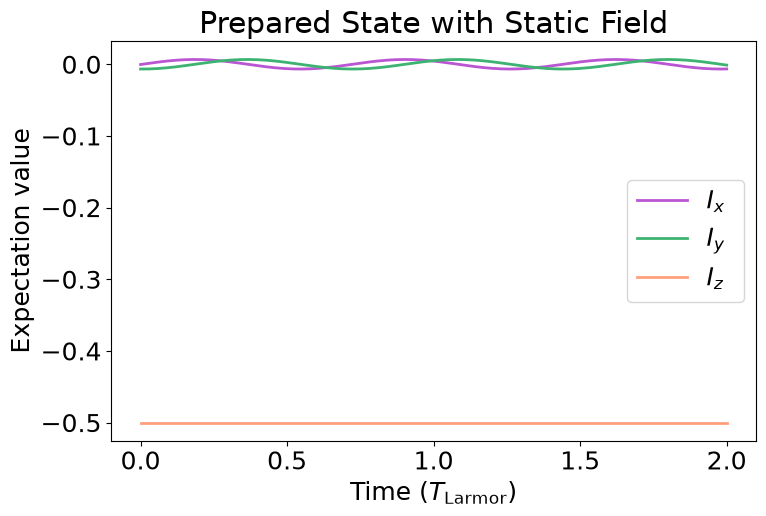

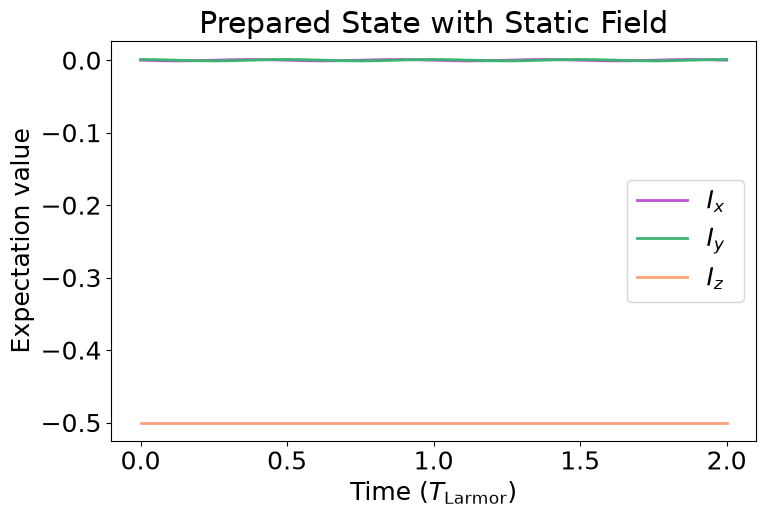

In [9]:
T_larmor = 1 / (gamma_n * 0.5)
t = np.linspace(0, 2 * T_larmor, 201)

cols = [ncols // 2, ncols // 2 + 10, ncols - 1]

print(f"T_Larmor = {T_larmor*1e9:.3f} ns")
print(hamiltonian[cols[0]])

for col in cols:
    psi = np.array(
        [expm(-1j * 2 * np.pi * hamiltonian[col] * tk) @ psi_pi2[col] for tk in t]
    )

    Ix_exp = np.real(np.einsum("...i,ij,...j->...", psi.conj(), I_x, psi))
    Iy_exp = np.real(np.einsum("...i,ij,...j->...", psi.conj(), I_y, psi))
    Iz_exp = np.real(np.einsum("...i,ij,...j->...", psi.conj(), I_z, psi))

    fig = plt.figure()
    ax = fig.add_subplot()
    label_col = f"{col - ncols // 2:03}"
    ax.plot(t / T_larmor, Ix_exp, label=r"$I_x$ ", color=colour1)
    ax.plot(t / T_larmor, Iy_exp, label=r"$I_y$ ", color=colour2)
    ax.plot(t / T_larmor, Iz_exp, label=r"$I_z$ ", color=colour3)

    # No Y limit so oscillations are more visible
    ax.set_title(f"Prepared State with Static Field")
    ax.set_xlabel(r"Time ($T_{\mathrm{Larmor}}$)")
    ax.set_ylabel(r"Expectation value")
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/single-spin-larmor-{label_col}.png")


### Question 1.9

t_max = 0.65 T_Larmor=30.6ns


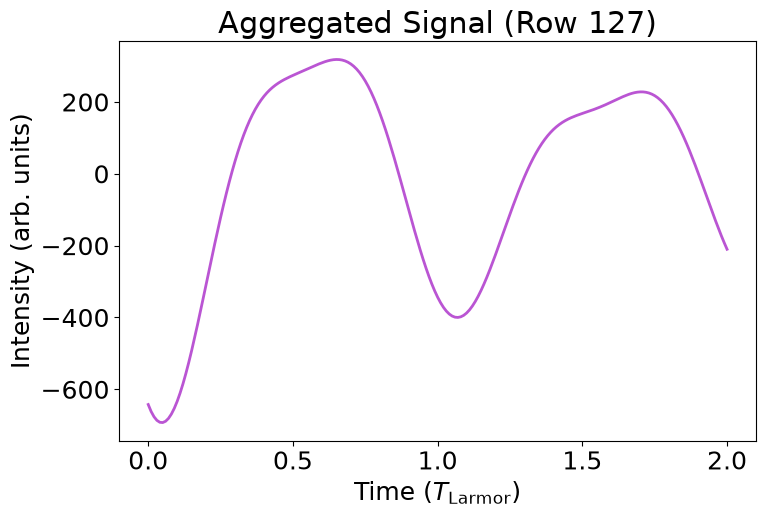

In [10]:
r = nrows // 2
t = np.linspace(0, 2 * T_larmor, 201)

psi = np.empty((len(t), ncols, 2), dtype=complex)
for col in range(ncols):
    for i, tk in enumerate(t):
        psi[i, col] = expm(-1j * 2 * np.pi * hamiltonian[col] * tk) @ psi_pi2[col]

Ix_all = np.real(np.einsum("tci,ij,tcj->tc", psi.conj(), I_x, psi))

P = Ix_all @ img[r, :]

fig, ax = plt.subplots()
ax.plot(t / T_larmor, P, color=colour1)
ax.set_title(f"Aggregated Signal (Row {r})")
ax.set_xlabel(r"Time ($T_{\mathrm{Larmor}}$)")
ax.set_ylabel("Intensity (arb. units)")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/aggregate-spin-row.png")

t_max = t[np.argmax(P)]

print(f"t_max = {t_max/T_larmor:.2f} T_Larmor={t_max*1e9:.1f}ns")


### Question 1.10

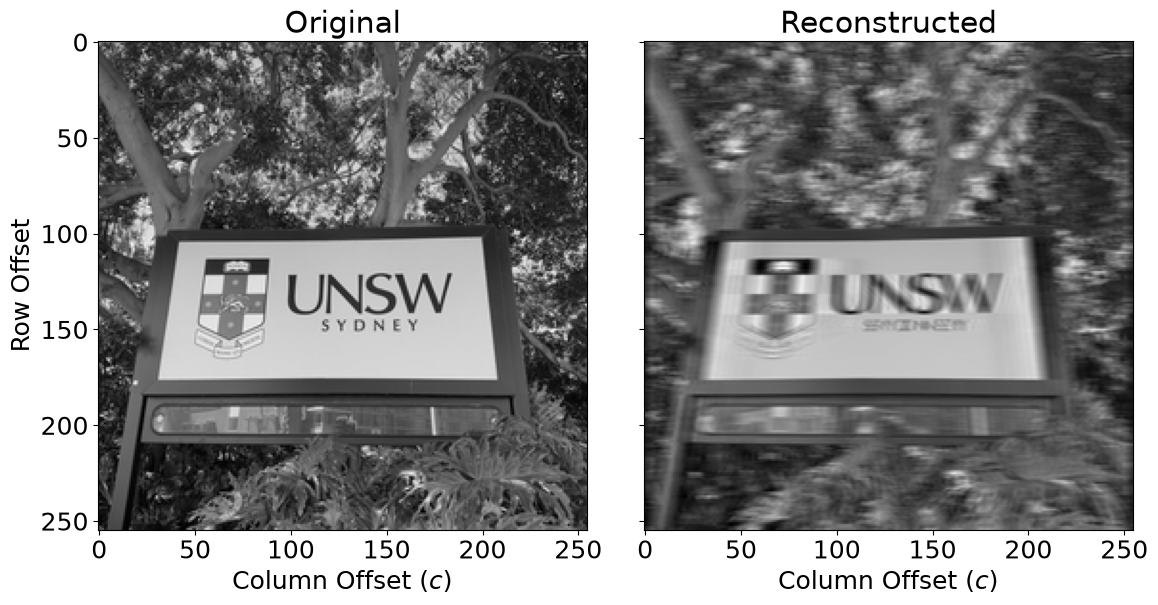

In [11]:
t_read = t_max
psi0 = d_ket

recon = np.zeros((nrows, ncols))

for k, mu in enumerate(c):
    Bz = B_z(c, mu)
    delta = gamma_n * Bz - f_drive
    H_rot = delta[:, None, None] * I_z + omega_R * I_x

    U_pulse = expm(-1j * 2 * np.pi * H_rot * t_pi2)
    psi = np.einsum("cij,j->ci", U_pulse, psi0)

    H_lab = gamma_n * Bz[:, None, None] * I_z
    U_lab = expm(-1j * 2 * np.pi * H_lab * t_read)
    psi = np.einsum("cij,cj->ci", U_lab, psi)

    Ix = np.real(np.einsum("ci,ij,cj->c", psi.conj(), I_x, psi))
    # w = np.abs(c - mu) <= 10
    # recon[:, k] = img[:, w] @ Ix[w]
    recon[:, k] = img @ Ix

fig, axs = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
axs[0].imshow(img, cmap="gray")
axs[0].set_title("Original")
axs[1].imshow(recon, cmap="gray")
axs[1].set_title("Reconstructed")
axs[0].set_ylabel("Row Offset")
axs[0].set_xlabel(r"Column Offset ($c$)")
axs[1].set_xlabel(r"Column Offset ($c$)")
fig.tight_layout()
fig.savefig(f"{OUT_DIR}/reconstruction.png")
